# Hyperion integrated 6DOF trajectory

The current rigid-body model is shared by all verification notebooks. Inputs were synchronized on **28 October 2026**. Run this notebook first; the other notebooks reuse its flight history only while the model/data/configuration fingerprints match.

Edit `config/trajectory.json` for persistent changes. The input cell below shows the active configuration. Full equations are in `hyperion/trajectory.py`; the notebook contains no encoded data or long configuration dump.

**Current source conflict:** sizing selects an 11.5 m fairing and 58.763 m vehicle; the master payload tab still says 14 m. CP datum, aero geometry and actuator capability remain provisional. See `data/source_manifest.json`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from hyperion.workspace import current_flight
from hyperion.verification import ROOT, activities, input_contracts

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_colwidth', 100)

## Inputs and execution

Units are SI except the explicitly labelled degree/g fields. For an edited case, use `load_config()`, change values, and call `run_trajectory(config)`. The canonical result below uses the saved current configuration. Set `RECOMPUTE = True` to force a new integration.

In [2]:
from hyperion.trajectory import load_config, run_trajectory
RECOMPUTE = False
context = current_flight(recompute=RECOMPUTE)
flight, summary, model = context
config = model.c
display(pd.DataFrame([
    ('Payload', config['vehicle']['payload_kg'], 'kg'),
    ('Vehicle length', sum(s['length_m'] for s in config['vehicle']['stages']), 'm'),
    ('Wind at 10 m', config['atmosphere']['wind_reference_m_s'], 'm/s'),
    ('Axial acceleration limit', config['limits']['axial_g'], 'g'),
    ('Lateral acceleration limit', config['limits']['lateral_g'], 'g'),
    ('Commanded AoA limit', config['guidance']['aoa_command_limit_deg'], 'deg'),
    ('RK45 relative tolerance', config['solver']['rtol'], '1'),
], columns=['Input', 'Value', 'Unit']))

,Input,Value,Unit
0,Payload,4.313000e+03,kg
1,Vehicle length,5.876301e+01,m
2,Wind at 10 m,7.620000e+00,m/s
3,Axial acceleration limit,6.000000e+00,g
4,Lateral acceleration limit,2.000000e+00,g
5,Commanded AoA limit,2.000000e+00,deg
6,RK45 relative tolerance,2.000000e-07,1


## Model

The state contains ECI position/velocity, a body-to-ECI quaternion, three body rates, two propellant inventories, two gimbal angles and integrated loss terms. RK45 integrates translation and Euler rigid-body rotation between staging/cutoff events. A layered atmosphere, rotating Earth and configurable wind determine air-relative Mach and AoA. The Mach/AoA table is linearly interpolated; endpoint holds and configuration proxies are flagged.

Draining equivalent tank columns update center of mass and inertia. Throttle and TVC follow acceleration, travel and slew limits. Separation applies an explicit impulse and mass change; detailed relative-body clearance is evaluated separately. Powered and unpowered control margins are both retained.

In [3]:
from hyperion.flight_evidence import flight_summary
metrics = flight_summary(context)
display(pd.DataFrame([
    ('Max-Q', metrics['max_q_Pa']/1000, 'kPa'),
    ('Max-Qα', metrics['max_qalpha_Pa_deg']/1000, 'kPa deg'),
    ('AoA at max-Qα', metrics['alpha_at_max_qalpha_deg'], 'deg'),
    ('Peak axial acceleration', metrics['max_axial_g'], 'g'),
    ('Peak lateral acceleration', metrics['max_lateral_g'], 'g'),
    ('Liftoff thrust/weight', metrics['liftoff_thrust_to_weight'], '1'),
    ('Minimum powered control margin', metrics['minimum_powered_control_ratio_margin_Nm'], 'N m'),
    ('Minimum all-phase control margin', metrics['minimum_control_ratio_margin_Nm'], 'N m'),
], columns=['Metric', 'Result', 'Unit']).round(4))

,Metric,Result,Unit
0,Max-Q,17.8864,kPa
1,Max-Qα,31.7243,kPa deg
2,AoA at max-Qα,2.1770,deg
3,Peak axial acceleration,5.6884,g
4,Peak lateral acceleration,0.0179,g
5,Liftoff thrust/weight,1.3046,1
6,Minimum powered control margin,253760.4854,N m
7,Minimum all-phase control margin,-12765.9773,N m


## Flight, velocity and governing loads

Vertical markers identify max-Q, max-Qα and peak payload accelerations. Moment margin is available control minus **2 × aerodynamic moment**. A negative coast margin remains a failed screen; powered TVC does not supply engine-off torque.

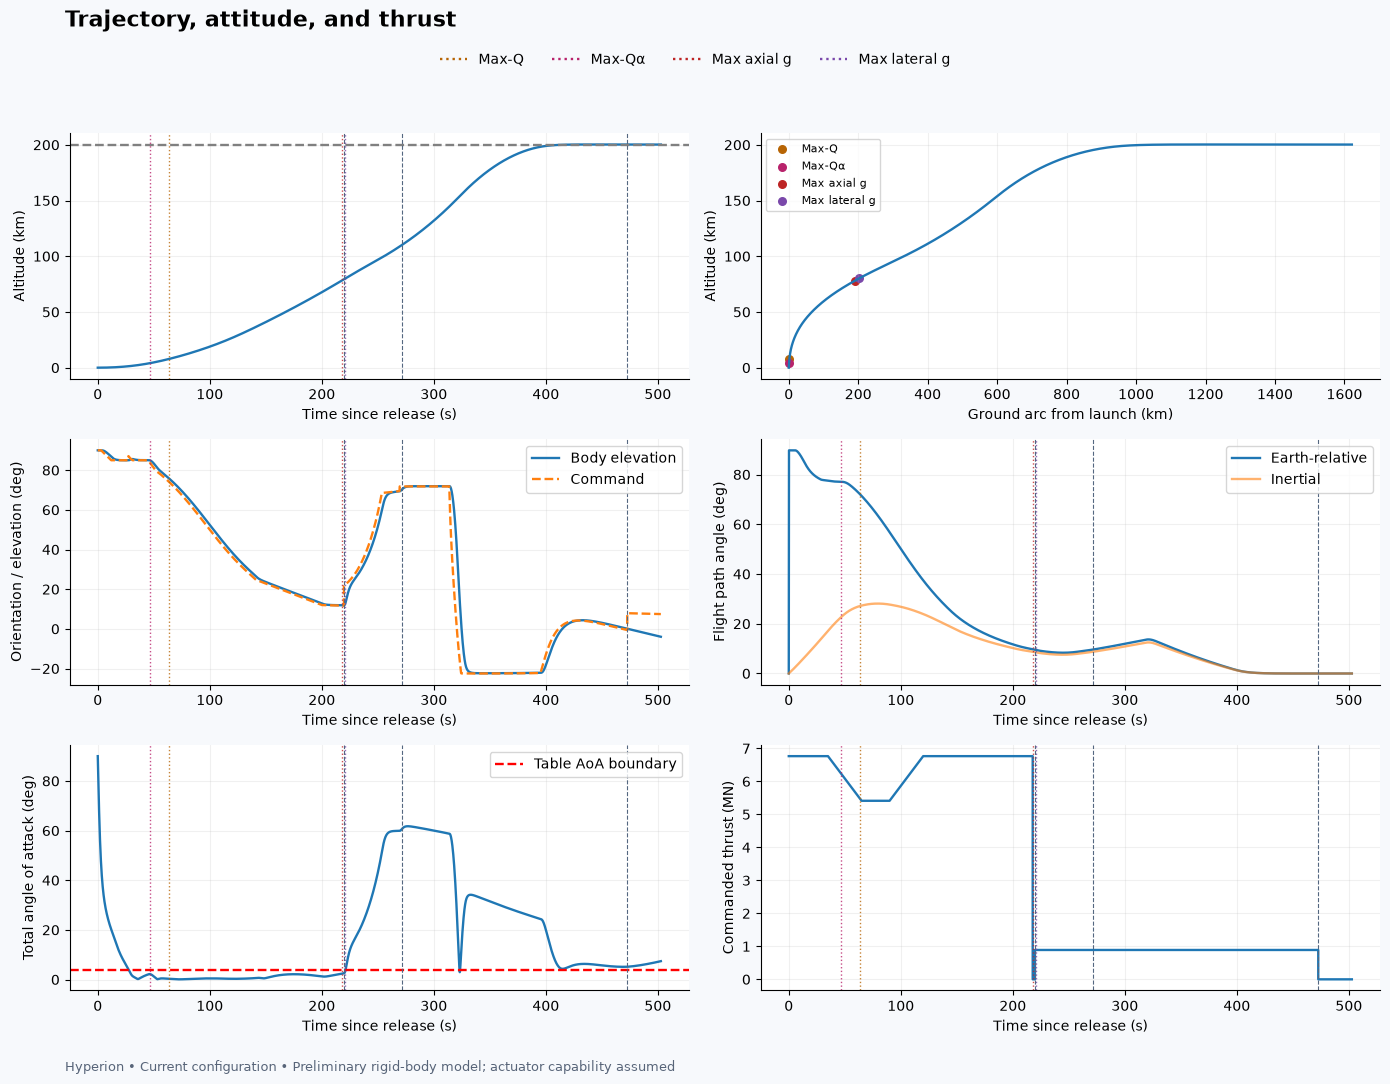

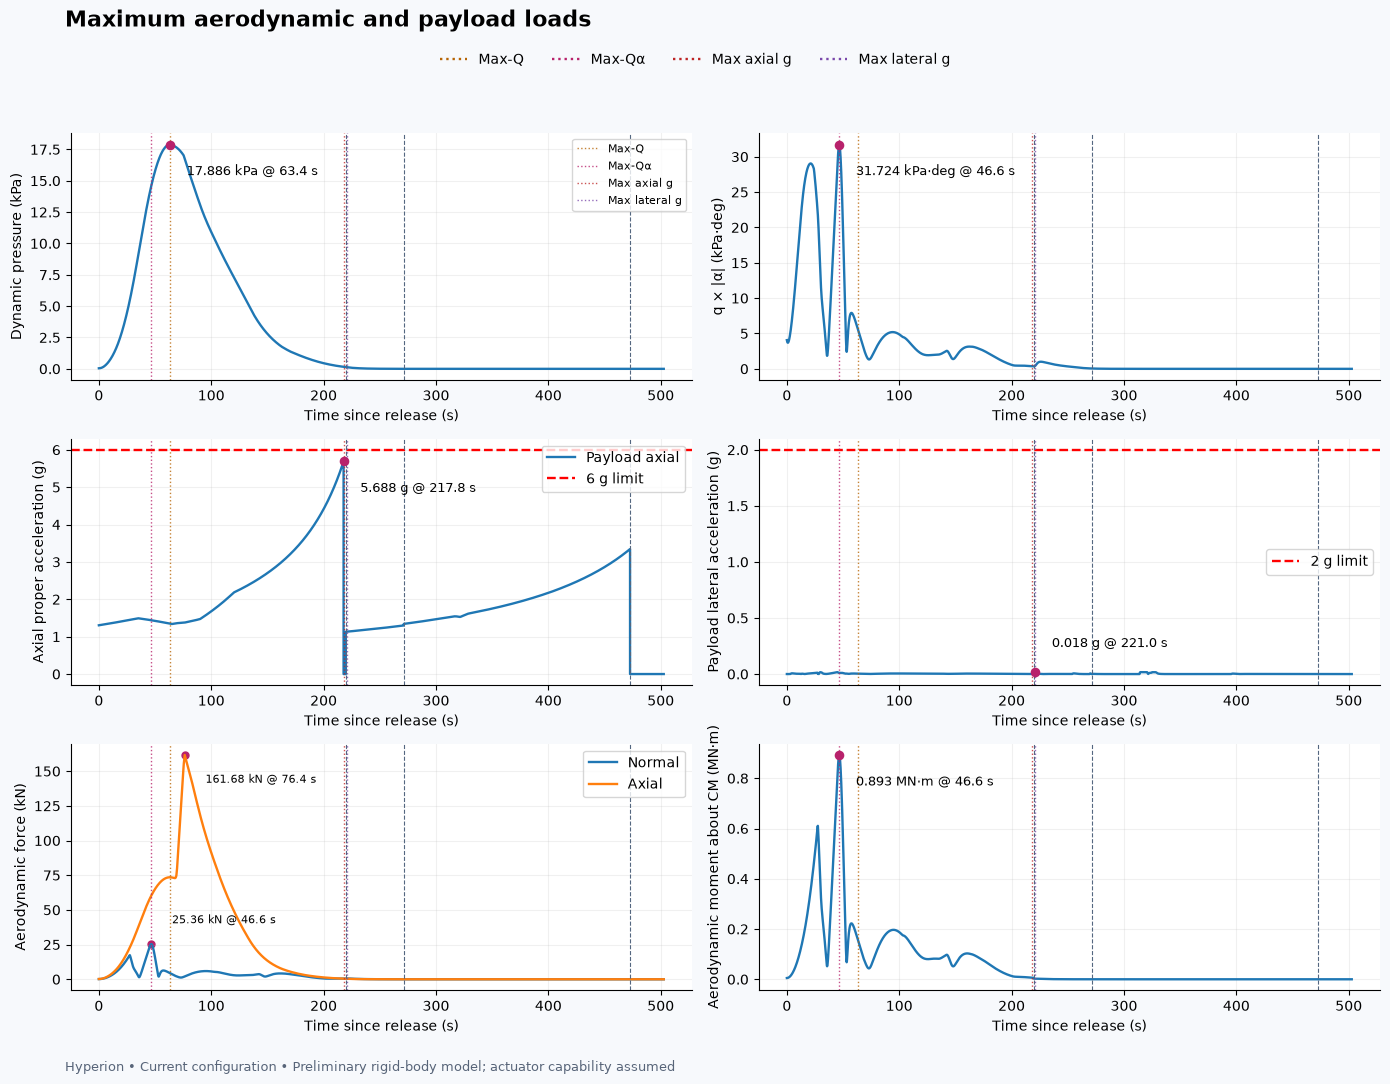

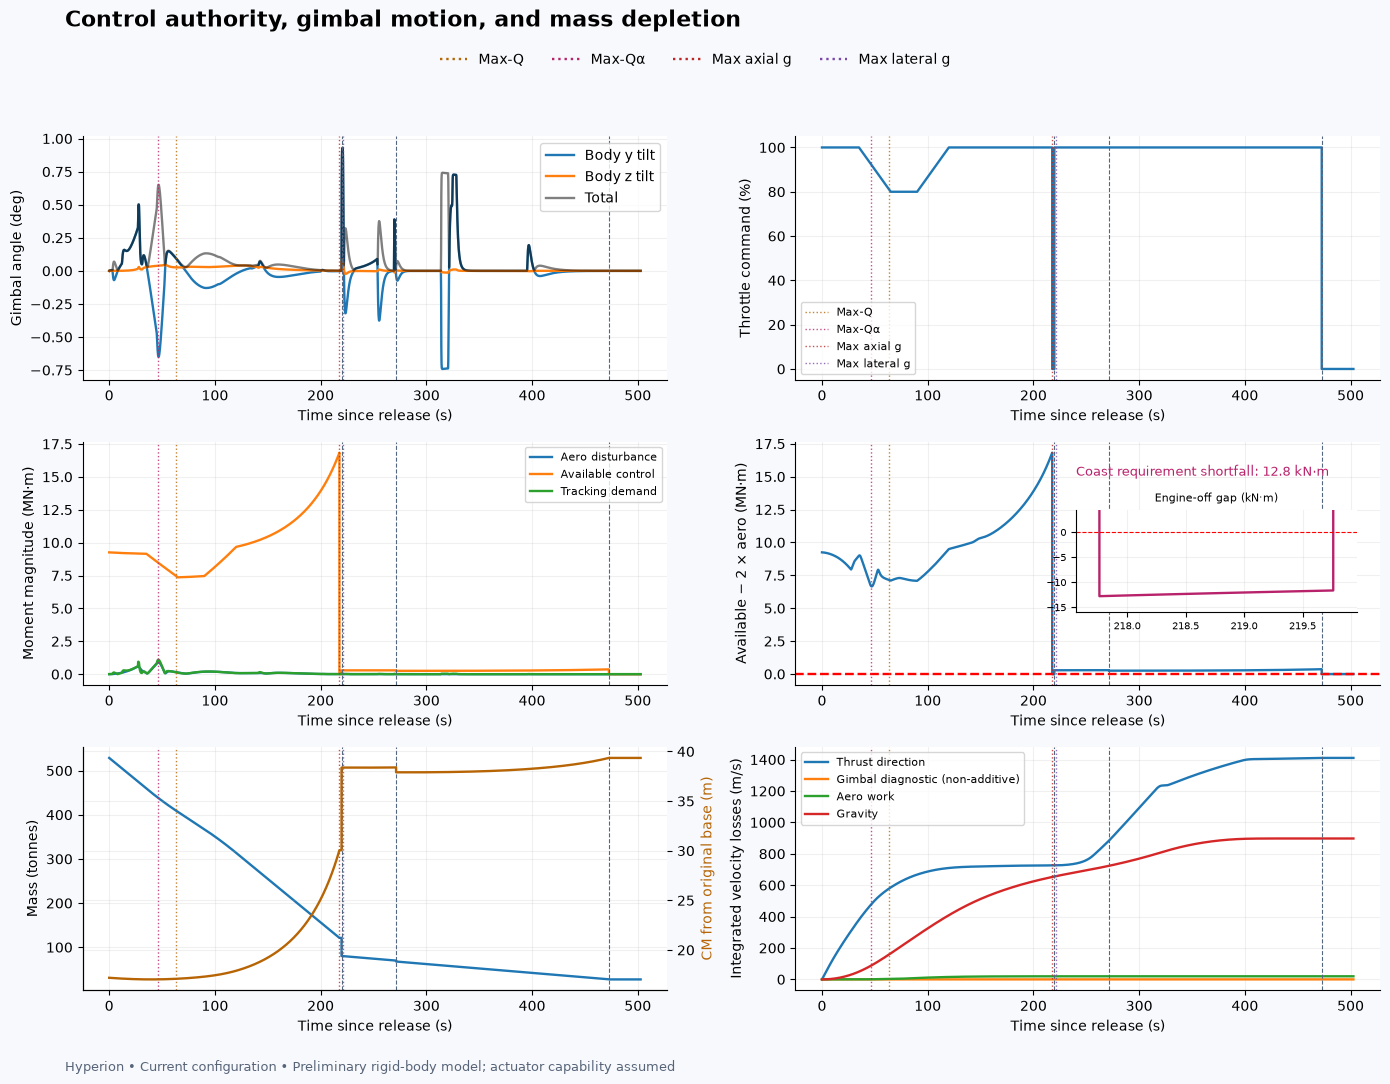

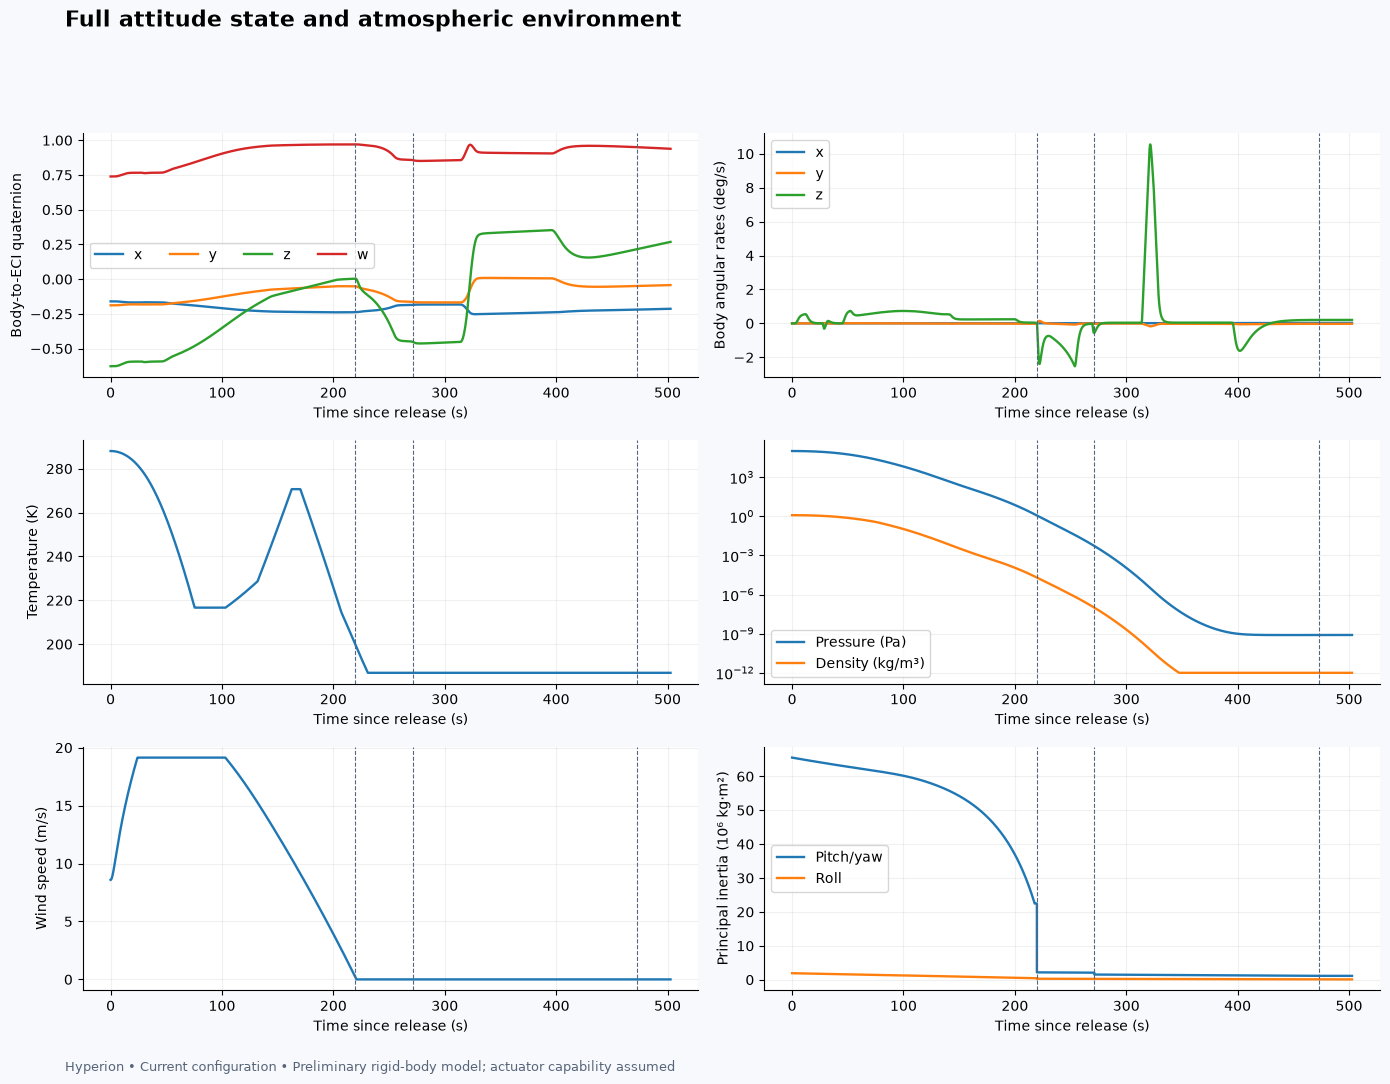

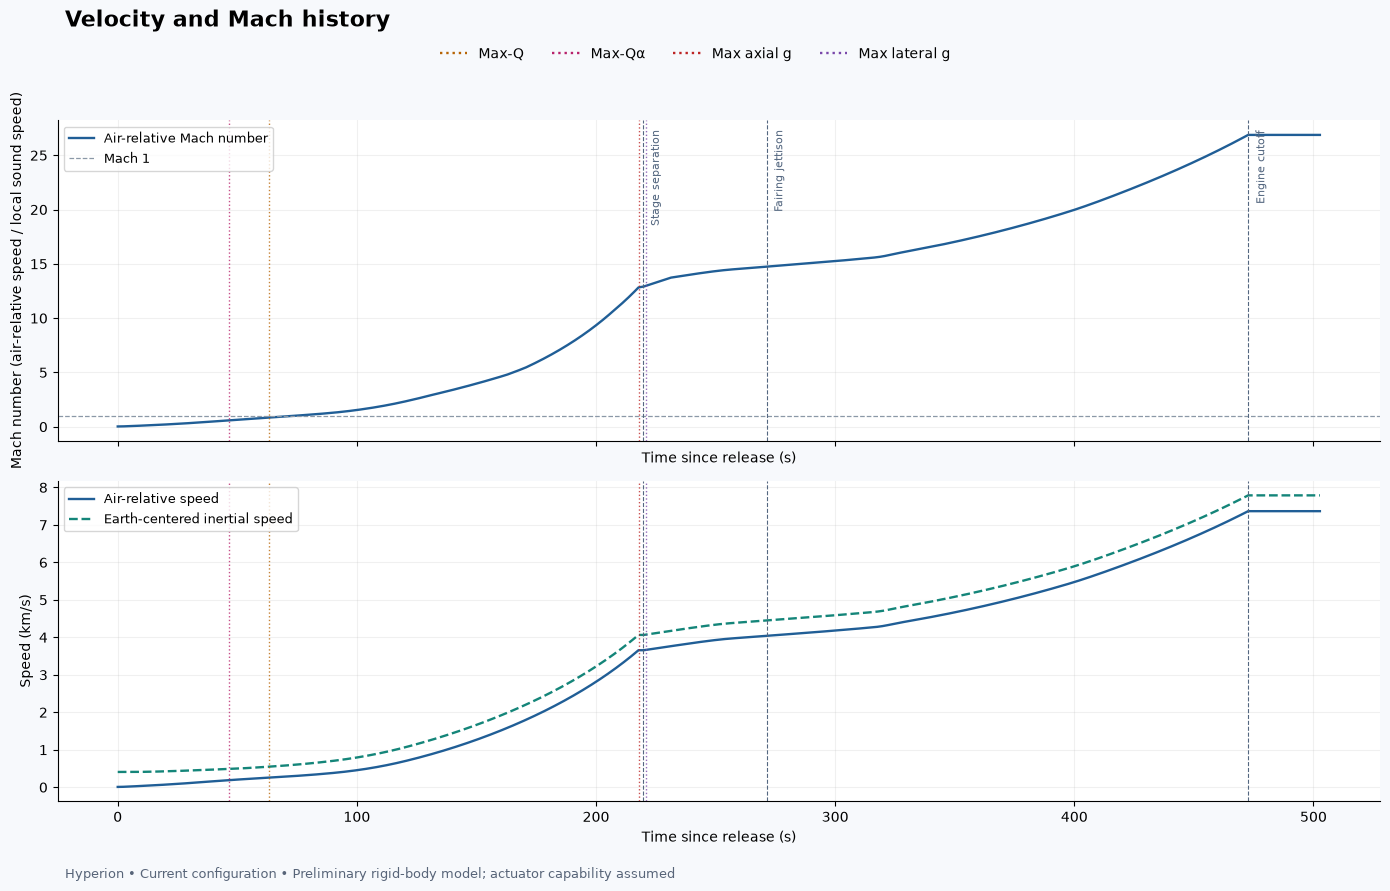

In [4]:
from hyperion.plotting import plot_results
figures = plot_results(flight, summary, config)
for figure in figures:
    display(figure)
    plt.close(figure)

## Verification handoff

The same trajectory supplies payload proper acceleration, force/moment histories, mass/CM, atmosphere, commands and event times to every other notebook. Rigid-body acceleration alone does not establish elastic coupled loads, vibration, shock or structural margins. The coast/restart/TMI notebook continues the same equations from the actual cutoff state.

In [5]:
display(model.load_cases[['case','t_s','altitude_m','mach','alpha_deg','q_Pa','axial_g','lateral_g']].round(3))
display(pd.DataFrame(summary['events']))

,case,t_s,altitude_m,mach,alpha_deg,q_Pa,axial_g,lateral_g
0,Max-Q,63.400,7787.302,0.834,0.308,17886.384,1.348,0.004
1,Max-Qalpha,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011
2,Max axial acceleration,217.763,78223.853,12.830,2.273,162.961,5.688,0.001
3,Max lateral acceleration,220.963,80173.685,12.986,3.435,120.661,1.134,0.018
4,Max aerodynamic moment,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011
5,Max TVC demand,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011
6,Max thrust,0.000,18.201,0.025,90.000,45.112,1.305,0.000
7,Max aerodynamic normal force,46.600,4077.470,0.584,2.177,14572.727,1.440,0.011
8,Max aerodynamic axial force,76.400,11291.113,1.051,0.119,16754.353,1.377,0.002


,event,t_s,shed_mass_kg,cg_shift_m,upper_delta_v_m_s,lower_delta_v_m_s
0,liftoff,0.000000,NaN,NaN,NaN,NaN
1,MECO,217.762831,NaN,NaN,NaN,NaN
2,stage_separation,219.762831,40744.129012,8.324391,0.5,-0.987756
3,stage2_ignition,219.762831,NaN,NaN,NaN,NaN
4,fairing_jettison,271.358436,2155.278250,NaN,NaN,NaN
5,orbital_speed_cutoff,472.676346,NaN,NaN,NaN,NaN
6,end_coast,502.676346,NaN,NaN,NaN,NaN


Numerical checks are run with `python -m unittest discover -s tests`. The historical Oct26 case is preserved as a regression fixture, while the current geometry is tested independently. A convergence check is available below; it compares a finer solver run, not a second physical model.

In [6]:
RUN_REFINEMENT = False
if RUN_REFINEMENT:
    import copy
    refined = copy.deepcopy(config)
    refined['solver']['rtol'] /= 10
    refined['solver']['max_step_s'] /= 2
    refined['solver']['output_step_s'] = 0.05
    fine, fine_summary, _ = run_trajectory(refined)
    display(pd.DataFrame({'nominal': flight[['q_Pa','qalpha_Pa_deg','axial_g','lateral_g']].max(),
                          'refined': fine[['q_Pa','qalpha_Pa_deg','axial_g','lateral_g']].max()}))